In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# importing featured engineer train and test data

X_train_fe = pd.read_csv('../Dataset/X_train_fe.csv')
X_test_fe = pd.read_csv('../Dataset/X_test_fe.csv')
X_train = pd.read_csv('../Dataset/X_train.csv')
X_test = pd.read_csv('../Dataset/X_test.csv')
y_train = pd.read_csv('../Dataset/y_train.csv')
y_test = pd.read_csv('../Dataset/y_test.csv')

In [3]:
print('X_train_fe Features:', X_train_fe.shape[1])
print('X_train_fe Columns:', X_train_fe.columns)
print()

print('X_train Features:', X_train.shape[1])
print('X_train Columns:', X_train.columns)

X_train_fe Features: 20
X_train_fe Columns: Index(['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
       'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'color', 'total_acidity', 'acidity_ratio',
       'extra_sulphur_dioxide', 'sulphur_dioxide_ratio', 'sugar_alcohol_ratio',
       'density_alcohol_ratio', 'alcohol_sulphates', 'alcohol_acidity'],
      dtype='str')

X_train Features: 12
X_train Columns: Index(['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
       'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'color'],
      dtype='str')


In [4]:
# convert into a series

y_train = y_train.squeeze()
y_test = y_test.squeeze()

In [6]:
# checking for constant features

constant_features = [
    col for col in X_train_fe.columns
    if X_train_fe[col].nunique == 1
]

print("Constant Features:", constant_features)

Constant Features: []


In [7]:
# highly related features columns

corr_matrix = X_train_fe.corr().abs()

upper_matrix = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

highly_corr_features = [
    col for col in upper_matrix.columns
    if any(upper_matrix[col] > 0.90)    
]

print("High Correlated Features:", highly_corr_features)

High Correlated Features: ['total_acidity', 'extra_sulphur_dioxide', 'sugar_alcohol_ratio', 'density_alcohol_ratio', 'alcohol_sulphates']


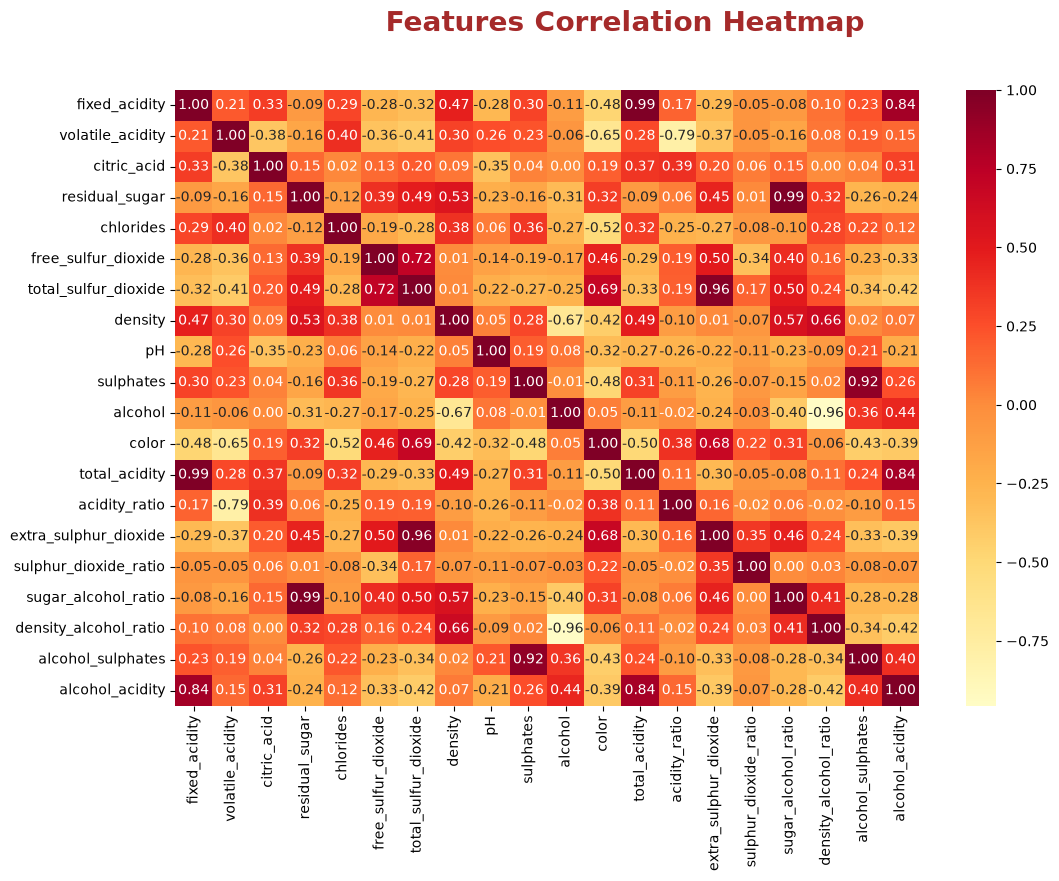

In [8]:
# highly related features columns visualization

plt.figure(figsize=(12, 8))

sns.heatmap(
    X_train_fe.corr(),
    annot=True,
    cmap='YlOrRd',
    center=0,
    fmt='.2f'
)

plt.suptitle(
    'Features Correlation Heatmap',
    fontsize=20,
    fontweight='bold',
    color='brown'
)
plt.show()

In [10]:
# check target correlation with features

corr_with_target = pd.concat([X_train_fe, y_train], axis=1).corr()['quality'].sort_values(ascending=False)
corr_with_target

quality                  1.000000
alcohol                  0.469144
alcohol_sulphates        0.226936
acidity_ratio            0.203036
alcohol_acidity          0.180522
color                    0.114271
citric_acid              0.106806
sulphates                0.054427
free_sulfur_dioxide      0.054426
pH                       0.025393
total_sulfur_dioxide    -0.049359
residual_sugar          -0.059516
fixed_acidity           -0.077343
extra_sulphur_dioxide   -0.083108
total_acidity           -0.092238
sugar_alcohol_ratio     -0.102190
sulphur_dioxide_ratio   -0.171343
chlorides               -0.212329
volatile_acidity        -0.263064
density                 -0.323682
density_alcohol_ratio   -0.448716
Name: quality, dtype: float64

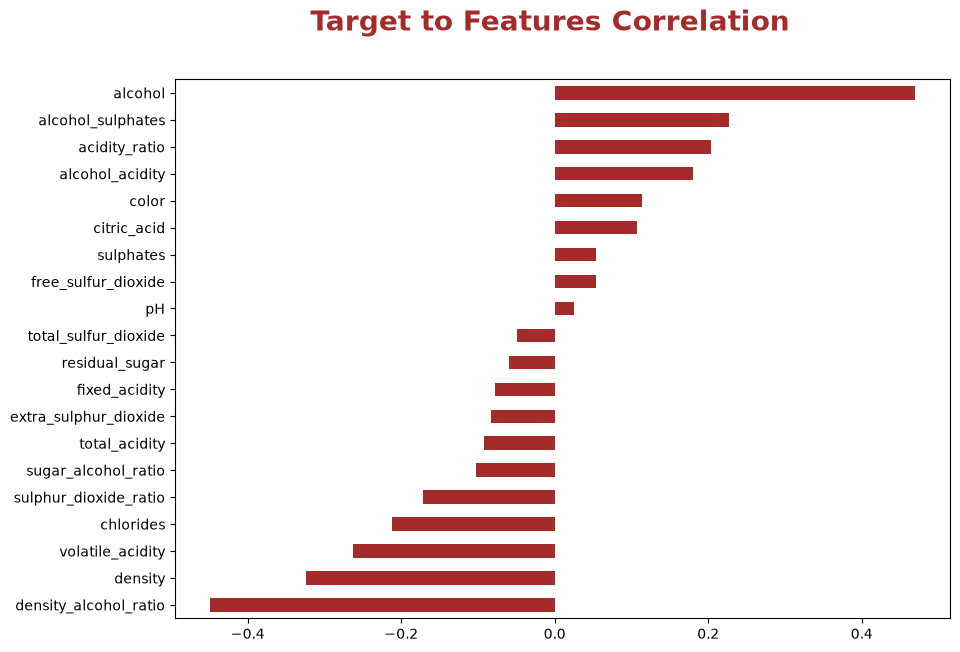

In [23]:
# target correlation with features visualization

plt.figure(figsize=(10, 7))
corr_with_target.drop('quality').sort_values().plot(kind='barh', color='brown')

plt.suptitle(
    'Target to Features Correlation',
    fontsize=20,
    fontweight='bold',
    color='brown'
)
plt.show()

In [11]:
corr_target = (
    pd.concat([X_train_fe, y_train], axis=1)
      .corr()['quality']
      .abs()
)

for feature in highly_corr_features:
    print(feature, corr_target[feature])

total_acidity 0.09223849474121214
extra_sulphur_dioxide 0.08310779857559394
sugar_alcohol_ratio 0.10219029995667919
density_alcohol_ratio 0.44871609680445157
alcohol_sulphates 0.22693613942775923


In [19]:
# train a quick model to check feature importance 

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train_fe, y_train)

importance_df = pd.DataFrame({
    'Features':X_train_fe.columns,
    'Importance':rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

importance_df

,Features,Importance
10,alcohol,0.244697
13,acidity_ratio,0.088055
15,sulphur_dioxide_ratio,0.071721
18,alcohol_sulphates,0.060775
5,free_sulfur_dioxide,0.057221
1,volatile_acidity,0.056430
8,pH,0.053111
4,chlorides,0.044627
2,citric_acid,0.040364
7,density,0.037709


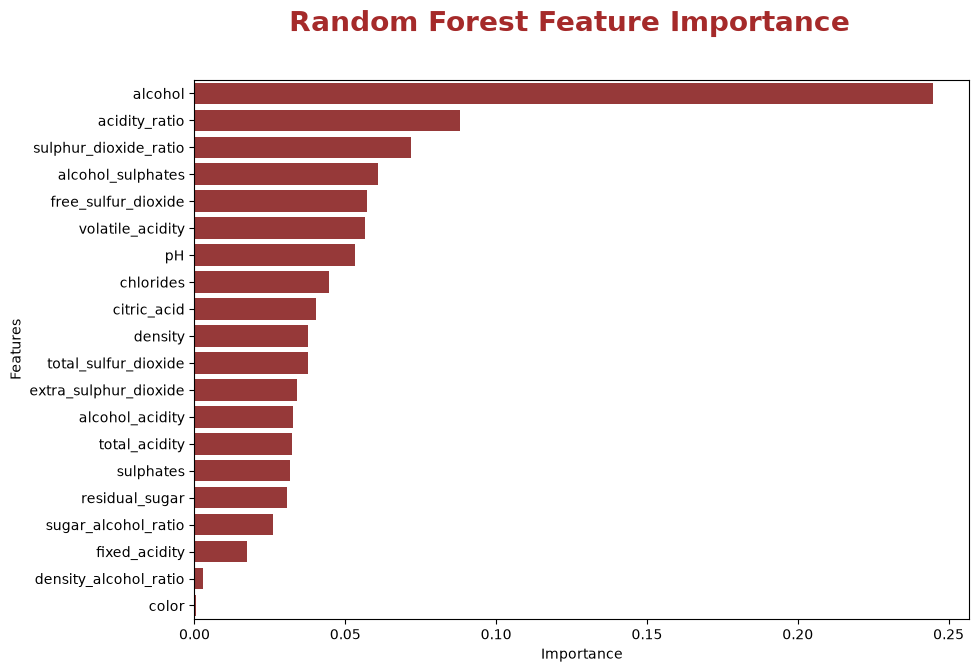

In [22]:
# random model feature importance visualization

plt.figure(figsize=(10, 7))

sns.barplot(
    importance_df,
    x='Importance',
    y='Features',
    color='brown'
)

plt.suptitle(
    'Random Forest Feature Importance',
    fontsize=20,
    fontweight='bold',
    color='brown'
)

plt.show()

In [24]:
# listing features to be dropped

features_to_drop = [
    'fixed_acidity',
    'extra_sulphur_dioxide',
    'sugar_alcohol_ratio',
    'density_alcohol_ratio',
    'sulphates'
]

In [25]:
# dropping features

X_train_fs = X_train_fe.drop(features_to_drop, axis=1)
X_test_fs = X_test_fe.drop(features_to_drop, axis=1)
X_train_fs.shape[1]

15

In [27]:
# test new train and test data

from sklearn.model_selection import cross_validate

fs_rf = RandomForestRegressor(random_state=42)
cv = cross_validate(
    fs_rf,
    X_train_fs,
    y_train,
    cv=3,
    scoring={
        'r2': 'r2',
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error'
    }
)